# **Problem Set 3**
## CHEM 5541 - Chemical Dynamics
### *Samuel Arnold*
### *9/18/26*
***

## 1.) Stern-Volmer Analysis

### 1a.)

$$\frac{d[\text{Br}^*]}{dt} = -k_1[\text{Br}^*][\text{HCl}] - k_2[\text{Br}^*][\text{Br}_2]$$

$$\frac{d[\text{Br}^*]}{dt} = -(k_1[\text{HCl}] + k_2[\text{Br}_2])[\text{Br}^*]$$

Since $[\text{Br}^*] << [\text{Br}_2], [\text{HCl}]$, the concentrations of the quenchers can be said to remain constant. Which allows us to create an effective rate constant, $k_{eff}$

$$\frac{d[\text{Br}^*]}{dt} = -k_{eff}[\text{Br}^*]$$

Which through integration:

$$[\text{Br}^*(t)] = e^{-k_{eff}(t-t_0)}$$

$$[\text{Br}^*(t)] = e^{-k_{eff}(k_1[\text{HCl}] + k_2[\text{Br}_2])(t-t_0)}$$

### 1b.) 

$$k_{eff} = \frac{1}{\tau} = k_1[\text{HCl}] + k_2[\text{Br}_2]$$

The slope of this plot is $k_1$ with a y-intercept of $k_2[\text{Br}_2]$.

k1: 14501.01 m³/(mol*s)
k2: 10110.32 m³/(mol*s)


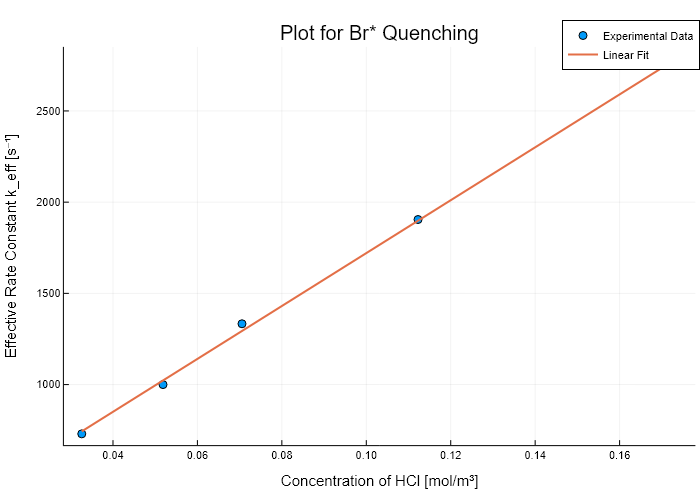

In [16]:
using Plots

plotlyjs()

R = 8.314        # J/(mol*K)
T = 300.0        # K

P_br2_torr = [0.5, 0.5, 0.5, 0.5, 0.5]
P_br2_pas = P_br2_torr .* 133.322
conc_br2 = P_br2_pas ./ (R * T)

P_hcl_torr = [0.61, 0.97, 1.32, 2.10, 3.25]
P_hcl_pas = P_hcl_torr .* 133.322
conc_hcl = P_hcl_pas ./ (R * T)

tau_us = [1370, 1000, 750, 525, 360]
tau_s = 1 ./ (tau_us .* 1e-6)

length_conc = length(conc_hcl)
avg_conc = sum(conc_hcl) / length_conc
avg_tau = sum(tau_s) / length_conc

numerator = sum((conc_hcl .- avg_conc) .* (tau_s .- avg_tau))
denominator = sum((conc_hcl .- avg_conc) .^ 2)

k1 = numerator / denominator
intercept = avg_tau - (k1 * avg_conc)

k2 = intercept / conc_br2[1]

conc_range = range(minimum(conc_hcl), maximum(conc_hcl), length=100)
fit_line = k1 .* conc_range .+ intercept

println("k1: ", round(k1, digits=2), " m³/(mol*s)")
println("k2: ", round(k2, digits=2), " m³/(mol*s)")

scatter(
    conc_hcl,
    tau_s,
    xlabel = "Concentration of HCl [mol/m³]",
    ylabel = "Effective Rate Constant k_eff [s⁻¹]",
    title = "Plot for Br* Quenching",
    label = "Experimental Data"
)

plot!(
    conc_range, 
    fit_line,
    label = "Linear Fit",
    linewidth = 2
)
